The pre-processing code is run at the start of the model building for easier access of variables.

(2193, 351)
0                  healthy
1                  healthy
2                  healthy
3                  healthy
4                  healthy
               ...        
2188    early stage cancer
2189    early stage cancer
2190    early stage cancer
2191    early stage cancer
2192    early stage cancer
Name: class_label, Length: 2193, dtype: object
class_label
early stage cancer        781
screening stage cancer    490
mid stage cancer          453
late stage cancer         409
healthy                    60
Name: count, dtype: int64
class_label
cancer     2133
healthy      60
Name: count, dtype: int64


[0 1]


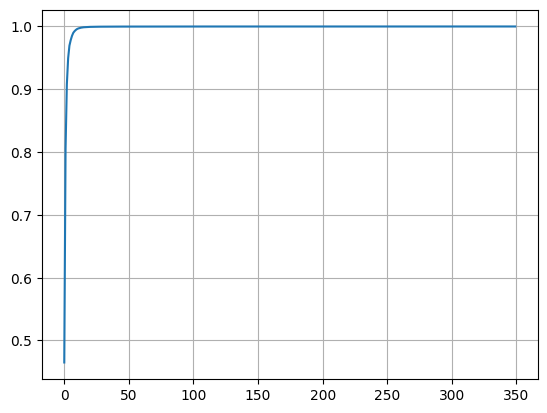

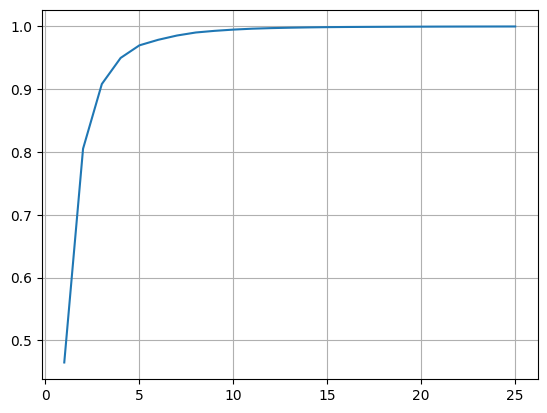

In [1]:
# --- project-root bootstrap: make this notebook CWD-independent (auto-added) ---
import os as _os
_root = _os.path.abspath(_os.getcwd())
while not _os.path.exists(_os.path.join(_root, 'data', 'raw', 'Train_Set.csv')) and _root != _os.path.dirname(_root):
    _root = _os.path.dirname(_root)
_os.chdir(_root)
# --- end bootstrap ---
import pandas as pd
import numpy as np
%run notebooks/01_data_prep_overview.ipynb

The RandomUnderSampler from the 'imblearn' package is used to randomly undersample the majority class, which is the proportion of the population with the cancer, such that the ratio of healthy to cancer is 1:1.

In [2]:
from imblearn.under_sampling import RandomUnderSampler
undersample = RandomUnderSampler(sampling_strategy = 1, random_state=42)
X_over, y_over = undersample.fit_resample(xvals_filtered, yvals_binary)

Gaussian Naive Bayes classifier is used, since the input variables are continuous. One assumption we make is that the values follow a normal distrubution. 

In [3]:
from sklearn.naive_bayes import GaussianNB
nb = GaussianNB()
nb.fit(X_over, y_over)
test_data = pd.read_csv('data/raw/Test_Set.csv')
test_data['class_label'] = test_data['class_label'].replace(['healthy', 'early stage cancer', 'screening stage cancer', 'mid stage cancer', 'late stage cancer'], [0, 1, 1, 1, 1])
testX, testY = test_data.drop(['class_label'], axis=1), test_data['class_label']
testX_filtered = testX.drop(columns=drops_2)
testX_over, testY_over = testX_filtered, testY  # evaluate on the real (imbalanced) test set
nb.score(testX_over, testY_over)

0.4622823984526112

The summary of the Gaussian Naive Bayes classifier is as shown below.

In [4]:
from sklearn.metrics import classification_report, confusion_matrix
y_pred = nb.predict(testX_over)
print(classification_report(testY_over, y_pred))
confusion_matrix(testY_over, nb.predict(testX_over))

              precision    recall  f1-score   support

           0       0.06      0.85      0.11        41
           1       0.99      0.45      0.61       993

    accuracy                           0.46      1034
   macro avg       0.52      0.65      0.36      1034
weighted avg       0.95      0.46      0.59      1034



array([[ 35,   6],
       [550, 443]])